# The insertions purged in warm gardens: where do they land? — allele unit, full spectrum

Corrected version of `sv_insertion_landing_vs_purging.ipynb`, which is kept unchanged for the record.

## What was wrong

The old notebook's tested set ("2,546 insertions, founder MAC 12–219, call rate ≥ 0.9"), the SV climate
slopes and the SNP reference they were ranked against all came from `lib.founder_panel_keep()`, a
**position-level** filter. It fails in two directions (table in the next section):

- **rare alleles admitted on a sibling's count** — at a multi-allelic position an allele passed if the record
  the filter looked at cleared the floor (the bug found 2026-09-18). 609 of the old 2,546 insertions had
  fewer than 12 carriers of their own (as few as 2) and 32 were called in < 90% of founders;
- **common alleles dropped** — the filter reads the pass status of *one* record per position (the first after
  an unstable sort, which can be a SNP at the same coordinate), not "any record". 1,343 insertions with ≥ 12
  carriers of their own (median 19) were excluded.

It also truncated the spectrum: MAC ≥ 12 and p0 ≥ 0.02 removed the rare tail, where the panel's CDS
depletion lives — so the frequency-spectrum panels of the purged set could not be compared with those of
all insertions.

## The rule here

One unit throughout — the allele (panel record) — and **one carrier floor for every row of the notebook**:
**2 ≤ own carriers ≤ 229**. Private (single-founder) records are dropped as possibly spurious; nothing else
is filtered — no call-rate floor, no p0 window — so the spectrum is otherwise complete. The same floor
defines the SNP reference (300,000 SNPs sampled from the 4.4 M that pass it).

Per-site `s`, the climate slope and both flags are recomputed from the pool AF matrices by
`_insertion_landing_vs_purging_rec.py` (`SV_FILTER=none SV_MIN_MAC=2`). Checks: re-running the old filter
through it reproduces the old 4,946 SVs and their betas exactly (corr = 1.00000); the new insertion betas
equal the no-filter-arm betas used in row 2 (corr = 1.00000); every insertion's own carrier count equals the
landing table's.

**"Purged more than a same-frequency SNP"** (flag A, unchanged definition): each insertion's climate slope
`beta(bio1) = d s / d bio1` is placed as a percentile within the `beta` of SNPs in its p0 bin; flagged =
percentile < 0.10. The matching is on **p0 only** — not on carrier-origin climate (see §2).

In [1]:

import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})

G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
os.makedirs(f"{G}/plots",exist_ok=True)
CLS=["CDS","UTR","exon_noncoding","intron","intergenic"]
CCOL={"CDS":"#D55E00","UTR":"#E69F00","exon_noncoding":"#009E73","intron":"#0072B2","intergenic":"0.55"}
FLAG="#B2182B"; REST="0.45"

def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88",lw=0.7,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def pfmt(p): return "< 1e-300" if p==0 else "= "+(f"{p:.1e}" if p<1e-3 else f"{p:.3f}")
def stat(ax,txt,loc=(0.03,0.03)):
    ax.annotate(txt,xy=loc,xycoords="axes fraction",fontsize=8.5,color="0.3")

TAG="_all2"                                           # record-level filter run (see title cell)
J=pd.read_csv(f"{G}/insertion_landing_vs_purging{TAG}.csv")
P=json.load(open(f"{G}/insertion_landing_vs_purging{TAG}.json"))
F,R=J[J.flagA],J[~J.flagA]
NFD=231; MAC=P["min_mac"]                              # one carrier floor for every row of the notebook
def floor(df): return df[(df.n_alt>=MAC)&(df.n_alt<=NFD-MAC)].reset_index(drop=True)
ALL0=pd.read_csv(f"{G}/insertion_context.csv"); ALL=floor(ALL0)
Z=np.load(f"{G}/insertion_context.npz",allow_pickle=True)
gfrac=dict(zip(Z["genome_frac_keys"].astype(str),Z["genome_frac"]))
EXP={"CDS":gfrac["CDS"],"UTR":gfrac["UTR"],
     "intron":max(gfrac["gene"]-gfrac["exon"],0),
     "exon_noncoding":max(gfrac["exon"]-gfrac["CDS"]-gfrac["UTR"],0),
     "intergenic":max(1-gfrac["gene"],0)}
A0=floor(pd.read_csv(f"{G}/insertion_beta_all.csv"))   # no-filter-arm beta for every insertion above the carrier floor
SIG=A0[(A0.beta_bio1<0)&(A0.beta_bio1_p<0.05)]
POS=A0[(A0.beta_bio1>0)&(A0.beta_bio1_p<0.05)]
DEL0=pd.read_csv(f"{G}/deletion_beta_all.csv").drop(columns=["tested","pct_beta1","flagA"])  # every deletion: context + no-filter beta
DEL=floor(DEL0)
DSIG=DEL[(DEL.beta_bio1<0)&(DEL.beta_bio1_p<0.05)]
DPOS=DEL[(DEL.beta_bio1>0)&(DEL.beta_bio1_p<0.05)]
DT=pd.read_csv(f"{G}/deletion_landing_vs_purging{TAG}.csv")   # tested deletions, record-level filter
DF=DT[DT.flagA]
assert (J.n_carriers_own>=P["min_mac"]).all() and (DT.n_carriers_own>=P["min_mac"]).all()
if P["filter"]=="record": assert J.call_rate.min()>=0.9
print(f"CARRIER FLOOR {MAC}..{NFD-MAC} own carriers everywhere: insertions {len(ALL0):,} -> {len(ALL):,}, "
      f"deletions {len(DEL0):,} -> {len(DEL):,} (private records dropped: {(ALL0.n_alt<MAC).sum():,} ins, {(DEL0.n_alt<MAC).sum():,} del)\n")
print(f"INSERTIONS  {len(ALL):,} in the panel; {len(J):,} tested; purged more than matched SNPs: {len(F)} ({100*len(F)/len(J):.1f}%)")
print(f"  beta(bio1) over {int(A0.n_sites.iloc[0])} sites: < 0 for {100*(A0.beta_bio1<0).mean():.1f}% (null 50%); "
      f"< 0 and p < 0.05: {len(SIG):,} ({100*len(SIG)/len(A0):.1f}%); > 0 and p < 0.05: {len(POS):,} ({100*len(POS)/len(A0):.1f}%); null 2.5% each side")
rule=("every record segregating in the panel (no carrier, call-rate or p0 filter)" if P["filter"]=="none"
      else f"own carriers >= {P['min_mac']}, call rate >= 0.9, {P['min_p0']} <= p0 <= {1-P['min_p0']}")
print(f"  tested = {rule}; own carriers {J.n_carriers_own.min()}..{J.n_carriers_own.max()}; "
      f"corr(seed-mix p0, founder freq) = {P['corr_p0_freq']:.3f}")
print(f"DELETIONS   {len(DEL):,} in the panel; {len(DT):,} tested; purged more than matched SNPs: {len(DF)} ({100*len(DF)/len(DT):.1f}%)")
print(f"  beta(bio1): < 0 for {100*(DEL.beta_bio1<0).mean():.1f}%; "
      f"< 0 and p < 0.05: {len(DSIG):,} ({100*len(DSIG)/len(DEL):.1f}%); > 0 and p < 0.05: {len(DPOS):,} ({100*len(DPOS)/len(DEL):.1f}%)")

# the SNP reference: same record-level filter and p0 window as the SVs (random SNP sample; no SNP beta below p0=0.02)
ZS=np.load(f"{G}/s_climate_slope{TAG}.npz"); isdel=ZS["sv_isdel"].astype(bool)
print(f"\nSNP REFERENCE ({P['n_snp_ref']:,} of {P['n_snp_pass']:,} SNPs passing the same filter): beta(bio1) < 0 for "
      f"SNPs {100*(ZS['beta_snp_bio1']<0).mean():.1f}% | "
      f"SV insertions {100*(ZS['beta_sv_bio1'][~isdel]<0).mean():.1f}% | SV deletions {100*(ZS['beta_sv_bio1'][isdel]<0).mean():.1f}%")
e=np.quantile(ZS["p0_snp"],np.linspace(0,1,6)); e[-1]+=1e-9
bs=np.digitize(ZS["p0_snp"],e[1:-1]); bi=np.digitize(ZS["p0_sv"][~isdel],e[1:-1]); bd=np.digitize(ZS["p0_sv"][isdel],e[1:-1])
print(f"{'p0 bin':<16}{'SNP':>8}{'insertion':>11}{'deletion':>10}")
for b_ in range(5):
    print(f"[{e[b_]:.3f},{e[b_+1]:.3f}) {100*(ZS['beta_snp_bio1'][bs==b_]<0).mean():>7.1f}%{100*(ZS['beta_sv_bio1'][~isdel][bi==b_]<0).mean():>10.1f}%{100*(ZS['beta_sv_bio1'][isdel][bd==b_]<0).mean():>9.1f}%")


CARRIER FLOOR 2..229 own carriers everywhere: insertions 172,220 -> 73,244, deletions 54,248 -> 32,101 (private records dropped: 98,975 ins, 22,141 del)

INSERTIONS  73,244 in the panel; 73,244 tested; purged more than matched SNPs: 10843 (14.8%)
  beta(bio1) over 31 sites: < 0 for 75.9% (null 50%); < 0 and p < 0.05: 25,859 (35.3%); > 0 and p < 0.05: 2,103 (2.9%); null 2.5% each side
  tested = every record segregating in the panel (no carrier, call-rate or p0 filter); own carriers 2..227; corr(seed-mix p0, founder freq) = 0.996
DELETIONS   32,101 in the panel; 32,101 tested; purged more than matched SNPs: 3734 (11.6%)
  beta(bio1): < 0 for 64.8%; < 0 and p < 0.05: 9,045 (28.2%); > 0 and p < 0.05: 2,132 (6.6%)

SNP REFERENCE (300,000 of 4,401,007 SNPs passing the same filter): beta(bio1) < 0 for SNPs 60.8% | SV insertions 75.9% | SV deletions 64.8%
p0 bin               SNP  insertion  deletion
[0.001,0.015)    59.1%      72.3%     63.9%


[0.015,0.030)    67.0%      78.1%     69.8%
[0.030,0.069)    65.8%      81.2%     70.5%
[0.069,0.217)    64.0%      77.3%     66.0%
[0.217,1.000)    48.1%      58.6%     50.3%


## What changed — the tested set under the old and the corrected filters

The same computation under four filters. `pos12` is the OLD position-level filter re-run through the new code
(control: reproduces the old notebook). `rec12` is the same floor judged on each allele's own carriers;
`rec2` adds the call-rate ≥ 0.9 and p0 ≥ 0.02 filters of `sv_purging_fixed.ipynb`; **`all2` is this notebook**
(≥ 2 own carriers, nothing else). `own<12` and `call<0.9` count members that the old filter's stated rules
would have excluded.

In [2]:

runs={}
for t in ("_pos12","_rec12","_rec2","_all2"):
    j=pd.read_csv(f"{G}/insertion_landing_vs_purging{t}.csv"); d=pd.read_csv(f"{G}/deletion_landing_vs_purging{t}.csv")
    runs[t]=(j,d)
print(f"{'run':<8}{'ins tested':>11}{'own<12':>10}{'call<0.9':>9}{'flag A':>8}{'%':>7}{'CDS % flagged':>15}{'CDS % rest':>12}{'del tested':>12}{'del flag A %':>13}")
for t,(j,d) in runs.items():
    f,r=j[j.flagA],j[~j.flagA]
    print(f"{t[1:]:<8}{len(j):>11,}{(j.n_carriers_own<12).sum():>10,}{(j.call_rate<0.9).sum():>9,}{j.flagA.sum():>8,}{100*j.flagA.mean():>6.1f}%"
          f"{100*(f.genic=='CDS').mean():>14.1f}%{100*(r.genic=='CDS').mean():>11.1f}%{len(d):>12,}{100*d.flagA.mean():>12.1f}%")
o,n=runs["_pos12"][0],runs["_rec12"][0]; so,sn=set(o.afrow),set(n.afrow)
print(f"\nold (pos12) vs correct (rec12) insertion sets: shared {len(so&sn):,}; old only {len(so-sn):,} "
      f"(own carriers < 12: {(o[~o.afrow.isin(sn)].n_carriers_own<12).sum()}); correct only {len(sn-so):,} "
      f"(median own carriers {n[~n.afrow.isin(so)].n_carriers_own.median():.0f} -- dropped by the old filter)")


run      ins tested    own<12 call<0.9  flag A      %  CDS % flagged  CDS % rest  del tested del flag A %
pos12         2,546       609       32     323  12.7%           5.6%        5.0%       2,400         9.8%
rec12         3,258         0        0     462  14.2%           4.3%        4.8%       2,477         9.9%
rec2          9,392     6,128        0   1,428  15.2%           5.7%        4.7%       3,881        10.1%
all2         73,244    63,725   49,901  10,843  14.8%           5.3%        5.3%      32,101        11.6%

old (pos12) vs correct (rec12) insertion sets: shared 1,915; old only 631 (own carriers < 12: 609); correct only 1,343 (median own carriers 19 -- dropped by the old filter)


## 0. Where SVs land: all of them, the ones declining with heat, the ones purged more than SNPs

The opening figure of `sv_insertion_content.ipynb`, repeated for three sets (one per row, named in
the y-axis label), first for insertions and then for deletions. Left: cumulative distribution of
ALT frequency among called founders, by landing class. Right: the share of variants in each class
(coloured) next to the share of the genome that class occupies (grey), with the ratio — 0.19× means
insertions land in CDS at a fifth of the rate the genome's CDS content would predict.

- **Row 1 — every variant** of that type in the founder panel with ≥ 2 own carriers.
- **Row 2 — climate slope negative and significant** (same carrier floor). `beta(bio1) = d s / d bio1`
  computed for every variant from the per-site `s` the no-filter arm stored (31 gardens, same
  across-site OLS as the production beta); `beta < 0` = declines more the hotter the garden;
  significance is a t-test on the slope over the 31 gardens, p < 0.05. Under no selection 2.5% of
  variants would land here; the matching significantly *positive* set is printed for contrast.
- **Row 3 — purged more than a same-frequency SNP** (`beta(bio1)` below the 10th percentile of p0-matched
  SNPs — the set used in §1–2). Row 3 is now a subset of row 1, so all three rows share one population.

With the full spectrum the three rows are nearly indistinguishable: the insertions purged more than matched
SNPs land like every insertion — CDS 5.3% in all three rows (0.19× the genome's share), ~77% intergenic — and
their frequency spectra by landing class have the same shape as row 1's.

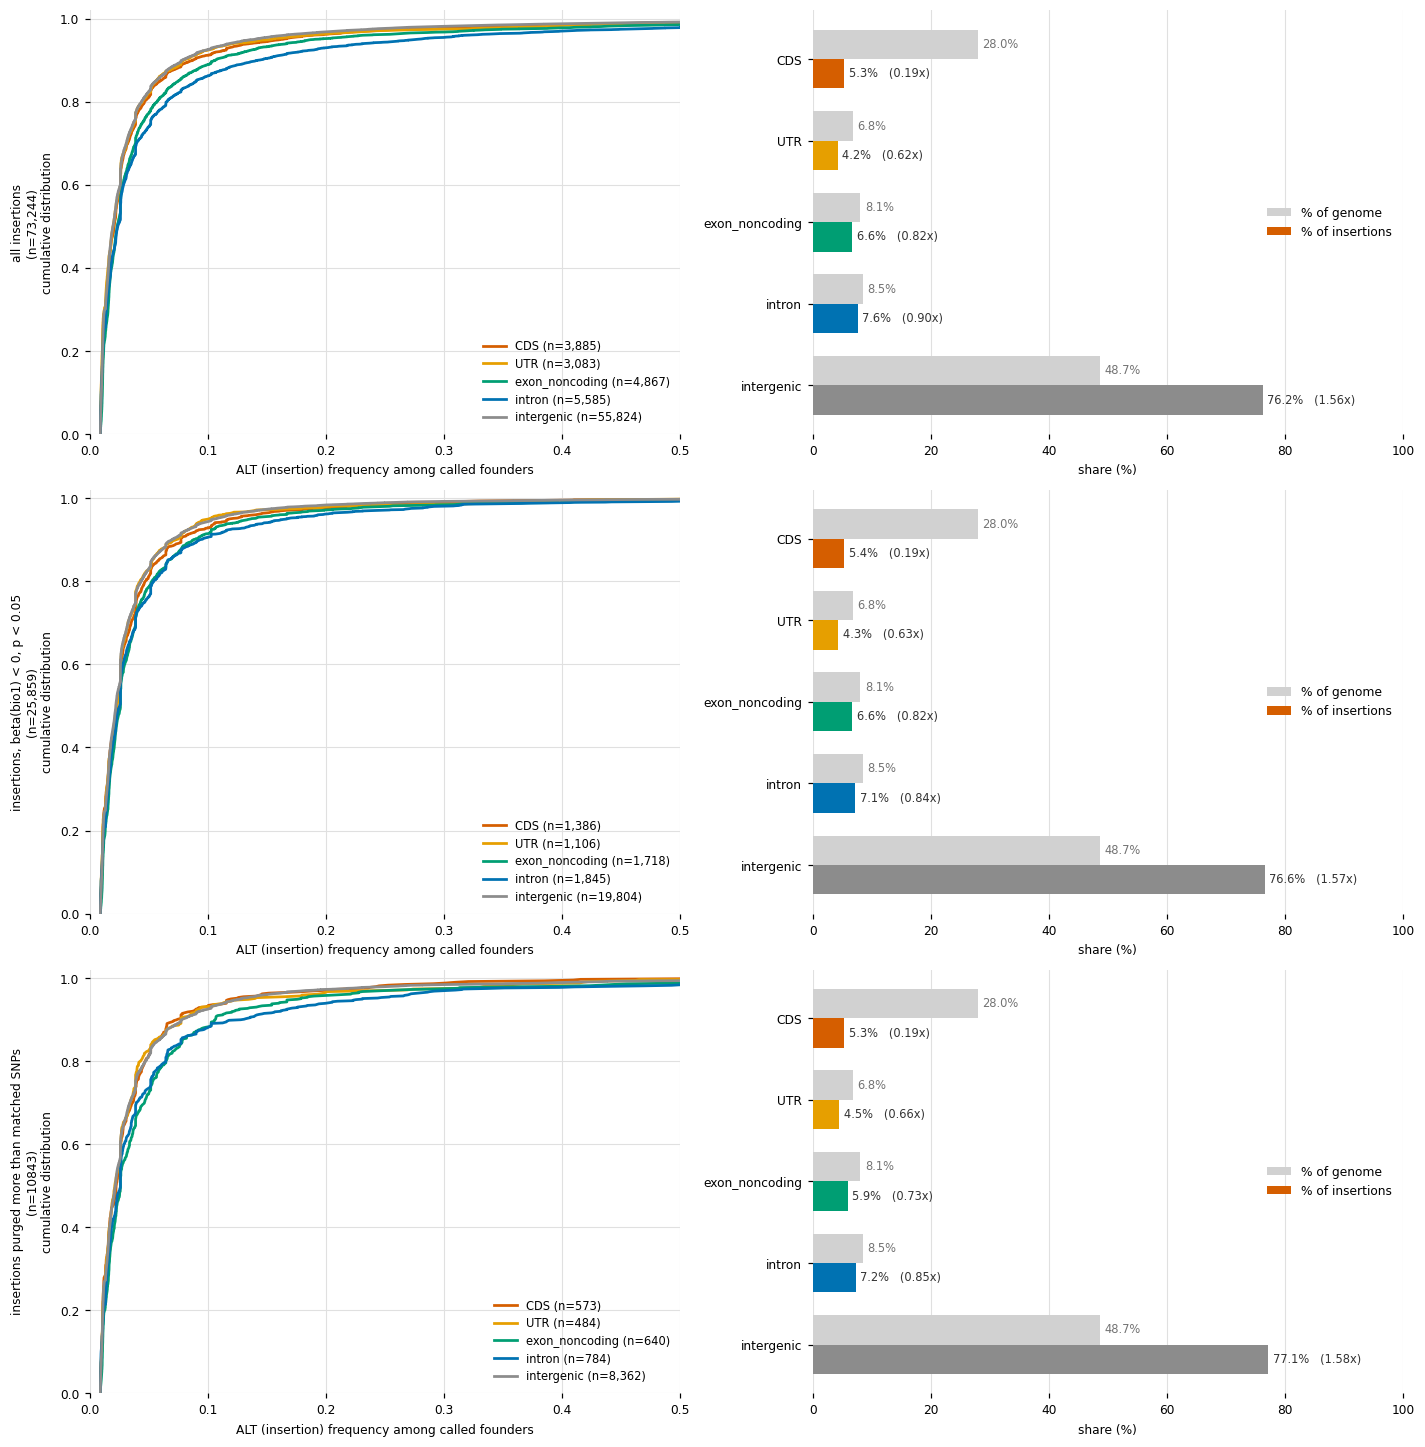

columns: [1] all insertions | [2] insertions, beta(bio1) < 0, p < 0.05 | [3] insertions purged more than matched SNPs
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         3,885   5.3%  0.19x         1,386   5.4%  0.19x           573   5.3%  0.19x
UTR                  6.8         3,083   4.2%  0.62x         1,106   4.3%  0.63x           484   4.5%  0.66x
exon_noncoding       8.1         4,867   6.6%  0.82x         1,718   6.6%  0.82x           640   5.9%  0.73x
intron               8.5         5,585   7.6%  0.90x         1,845   7.1%  0.84x           784   7.2%  0.85x
intergenic          48.7        55,824  76.2%  1.56x        19,804  76.6%  1.57x         8,362  77.1%  1.58x


In [3]:

def spectrum_and_share(ax_l,ax_r,D,ylab,kind="insertion"):
    style(ax_l)
    for c in CLS:
        v=np.sort(D.loc[D.genic==c,"freq"].values)
        if v.size==0: continue
        ax_l.plot(v,np.arange(1,v.size+1)/v.size,color=CCOL[c],lw=1.8,label=f"{c} (n={v.size:,})")
    ax_l.set_xlim(0,0.5); ax_l.set_ylim(0,1.02)
    ax_l.set_xlabel("ALT (insertion) frequency among called founders"); ax_l.set_ylabel(ylab)
    ax_l.legend(frameon=False,fontsize=7.5,loc="lower right")
    style(ax_r,axis="x")
    obs=D.genic.value_counts(normalize=True)
    yy=np.arange(len(CLS))[::-1]; h=0.36
    ax_r.barh(yy+h/2,[100*EXP[c] for c in CLS],height=h,color="0.82",linewidth=0,label="% of genome")
    ax_r.barh(yy-h/2,[100*obs.get(c,0) for c in CLS],height=h,color=[CCOL[c] for c in CLS],linewidth=0,label=f"% of {kind}s")
    for y,c in zip(yy,CLS):
        e=100*EXP[c]; o=100*obs.get(c,0)
        ax_r.annotate(f"{e:.1f}%",(e,y+h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.45")
        ax_r.annotate(f"{o:.1f}%   ({o/e:.2f}x)" if e>0 else f"{o:.1f}%",(o,y-h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.2")
    ax_r.set_yticks(yy); ax_r.set_yticklabels(CLS,fontsize=8); ax_r.set_xlim(0,100)
    ax_r.set_xlabel("share (%)"); ax_r.legend(frameon=False,fontsize=8,loc="center right")

def block(sets,kind,fname):
    fig,ax=plt.subplots(len(sets),2,figsize=(13,4.4*len(sets)))
    for i,(D,lab) in enumerate(sets):
        spectrum_and_share(ax[i,0],ax[i,1],D,lab+"\ncumulative distribution",kind)
        ax[i,0].set_xlabel(f"ALT ({kind}) frequency among called founders")
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()
    print("columns: " + " | ".join(f"[{i+1}] {lab.split(chr(10))[0]}" for i,(_,lab) in enumerate(sets)))
    print(f"{'class':<15}{'genome %':>9}"+"".join(f"{'['+str(i+1)+'] n':>14}{'%':>7}{'ratio':>7}" for i in range(len(sets))))
    for c in CLS:
        line=f"{c:<15}{100*EXP[c]:>9.1f}"
        for D,_ in sets:
            o=(D.genic==c).mean(); line+=f"{(D.genic==c).sum():>14,}{100*o:>6.1f}%{o/EXP[c]:>6.2f}x"
        print(line)

block([(ALL,"all insertions\n(n=%s)"%f"{len(ALL):,}"),
       (SIG,"insertions, beta(bio1) < 0, p < 0.05\n(n=%s)"%f"{len(SIG):,}"),
       (F,"insertions purged more than matched SNPs\n(n=%d)"%len(F))],
      "insertion","ins_spectrum_share_by_set_fixed"+TAG+".png")


### The same three rows for deletions

For a deletion the "site" is the removed interval `[pos, pos+ref_len)`, so it is classified by what
it **overlaps** (priority CDS > UTR > non-coding exon > intron; a deletion touching any coding base
is CDS). Two consequences for reading it against the insertion block: overlap probability grows with
length (median 363 bp, p99 31 kb) while the genome-share baseline is point-based, so the ratios run
higher than a point classification would give — the midpoint-based version is printed for
comparison; and `exon_noncoding` for deletions is largely **transposable-element genes** (they have
exons but no CDS in the TAIR10 GFF), i.e. deleted TE copies.

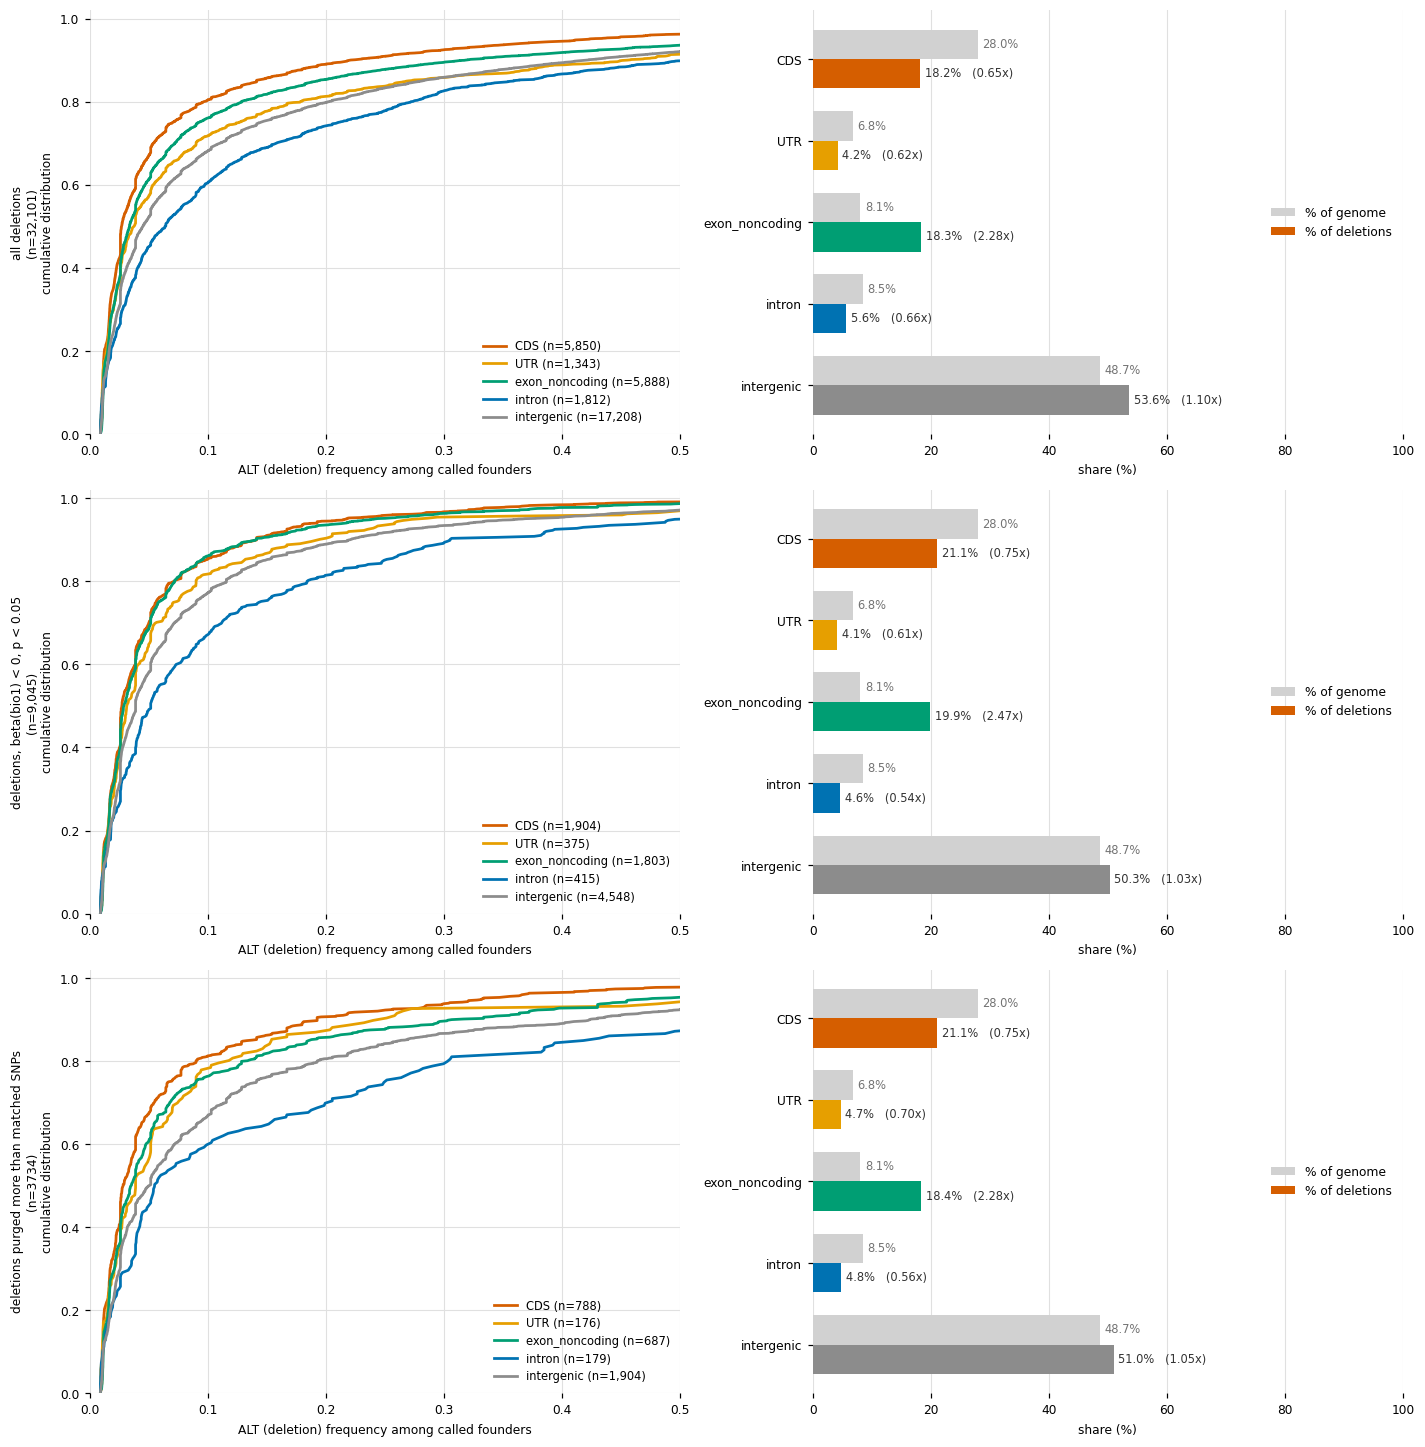

columns: [1] all deletions | [2] deletions, beta(bio1) < 0, p < 0.05 | [3] deletions purged more than matched SNPs
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         5,850  18.2%  0.65x         1,904  21.1%  0.75x           788  21.1%  0.75x
UTR                  6.8         1,343   4.2%  0.62x           375   4.1%  0.61x           176   4.7%  0.70x
exon_noncoding       8.1         5,888  18.3%  2.28x         1,803  19.9%  2.47x           687  18.4%  2.28x
intron               8.5         1,812   5.6%  0.66x           415   4.6%  0.54x           179   4.8%  0.56x
intergenic          48.7        17,208  53.6%  1.10x         4,548  50.3%  1.03x         1,904  51.0%  1.05x

midpoint-based class for deletions (point baseline, comparable to insertions):
class           genome %             all deletions             beta<0, p<.05            purged vs SNPs
CDS                 28.0        2,426    7.6% 0.

In [4]:

block([(DEL,"all deletions\n(n=%s)"%f"{len(DEL):,}"),
       (DSIG,"deletions, beta(bio1) < 0, p < 0.05\n(n=%s)"%f"{len(DSIG):,}"),
       (DF,"deletions purged more than matched SNPs\n(n=%d)"%len(DF))],
      "deletion","del_spectrum_share_by_set_fixed"+TAG+".png")

print("\nmidpoint-based class for deletions (point baseline, comparable to insertions):")
print(f"{'class':<15}{'genome %':>9}{'all deletions':>26}{'beta<0, p<.05':>26}{'purged vs SNPs':>26}")
for c in CLS:
    line=f"{c:<15}{100*EXP[c]:>9.1f}"
    for D in (DEL,DSIG,DF):
        o=(D.genic_mid==c).mean(); line+=f"{(D.genic_mid==c).sum():>13,}{100*o:>7.1f}%{o/EXP[c]:>5.2f}x"
    print(line)


### What the `beta < 0` fraction is made of — and the SNP reference

"Half negative under no selection" is the wrong null here. The setup cell prints the reference: under the same
carrier floor **SNPs are ~61% negative**, and the fraction depends on p0 (≈ 59–67% below p0 = 0.2, ≈ 48% above)
— a frequency-dependent baseline of the logit-slope estimator, which is why every comparison is made against
p0-matched SNPs. Against that baseline **insertions exceed SNPs in every p0 bin** (by 10–15 points), while
**deletions sit much closer to the SNP line** (+2 to +5 points). This insertion-specific excess is the result
the consolidated notebook reported; it survives the corrected filter and the full spectrum.

The table below breaks the no-filter-arm fractions down by seed-mix p0. The p0 ≤ 1e-3 stratum (identical
clipped starting logit — an artifact) is gone: dropping private records removed it.

In [5]:

A0["stratum"]=pd.cut(A0.p0,[0,1e-3,5e-3,0.02,0.05,0.2,1],labels=["<=1e-3","1e-3..5e-3","5e-3..0.02","0.02..0.05","0.05..0.2",">0.2"])
DEL["stratum"]=pd.cut(DEL.p0,[0,1e-3,5e-3,0.02,0.05,0.2,1],labels=["<=1e-3","1e-3..5e-3","5e-3..0.02","0.02..0.05","0.05..0.2",">0.2"])
g=pd.DataFrame({"ins n":A0.groupby("stratum",observed=True).size(),
                "ins frac beta<0":A0.groupby("stratum",observed=True).beta_bio1.apply(lambda x:(x<0).mean()),
                "del n":DEL.groupby("stratum",observed=True).size(),
                "del frac beta<0":DEL.groupby("stratum",observed=True).beta_bio1.apply(lambda x:(x<0).mean())})
print(f"fraction with beta(bio1) < 0, by seed-mix p0 (null = 0.50):\n{g.round(3).to_string()}")


fraction with beta(bio1) < 0, by seed-mix p0 (null = 0.50):
            ins n  ins frac beta<0  del n  del frac beta<0
stratum                                                   
1e-3..5e-3    883            0.488    154            0.377
5e-3..0.02  36013            0.742   9049            0.657
0.02..0.05  22829            0.802   8982            0.706
0.05..0.2   10855            0.789   8185            0.678
>0.2         2664            0.593   5731            0.508


### Where do the SVs carried by cold-origin ecotypes land?

`sv_founder_confound.ipynb` established that cold-origin ecotypes carry more inserted sequence
(kb absent from Col-0 vs origin bio1, ρ = −0.54). Here each variant gets the **mean origin bio1 of
the founders that carry it**, and the same three-row figure is drawn for **cold-carrier** and
**warm-carrier** variants next to all of them. No experimental data enters this section — it is
purely a founder-panel property.

The split follows `sv_insertion_content.ipynb` §2 exactly: `carrier_bio1` is coupled to frequency
(a rare variant's value is a few founders' origin; a common variant regresses to the panel mean), so
cold/warm are the bottom/top quartile of `carrier_bio1` **within carrier-count strata**
(n_alt 2–3 / 4–7 / 8–20 / 21+; private records are excluded throughout). Cold and warm sets therefore have the same frequency
distribution by construction, and the frequency-spectrum panels should look alike — the question
is the landing-class panel.

**Read the deletion block with the size check printed underneath.** Cold-carrier SVs are longer
than warm-carrier ones in every stratum (deletions: median 444 vs 284 bp at 2–3 carriers), and a
longer deletion is more likely to overlap *something*. The overlap-based CDS gap (cold > warm in
4/4 strata) shrinks to ≈ +1.4 pp once deletions are compared within size quintiles and disappears
on the midpoint classification — so it is mostly a length effect, not cold-origin deletions
targeting genes. For insertions, cold and warm land identically (CDS 5.2% vs 5.3%, flipping across
strata); the only consistent cold > warm difference is TE overlap of the site (4/4 strata), the
result already in `sv_insertion_content.ipynb` §2.

insertions: cold-carrier n=18,313 (median carrier bio1 5.8 C, median freq 0.0217) | warm-carrier n=18,313 (12.9 C, freq 0.0180)
deletions: cold-carrier n=8,026 (median carrier bio1 6.7 C, median freq 0.0385) | warm-carrier n=8,027 (12.9 C, freq 0.0370)


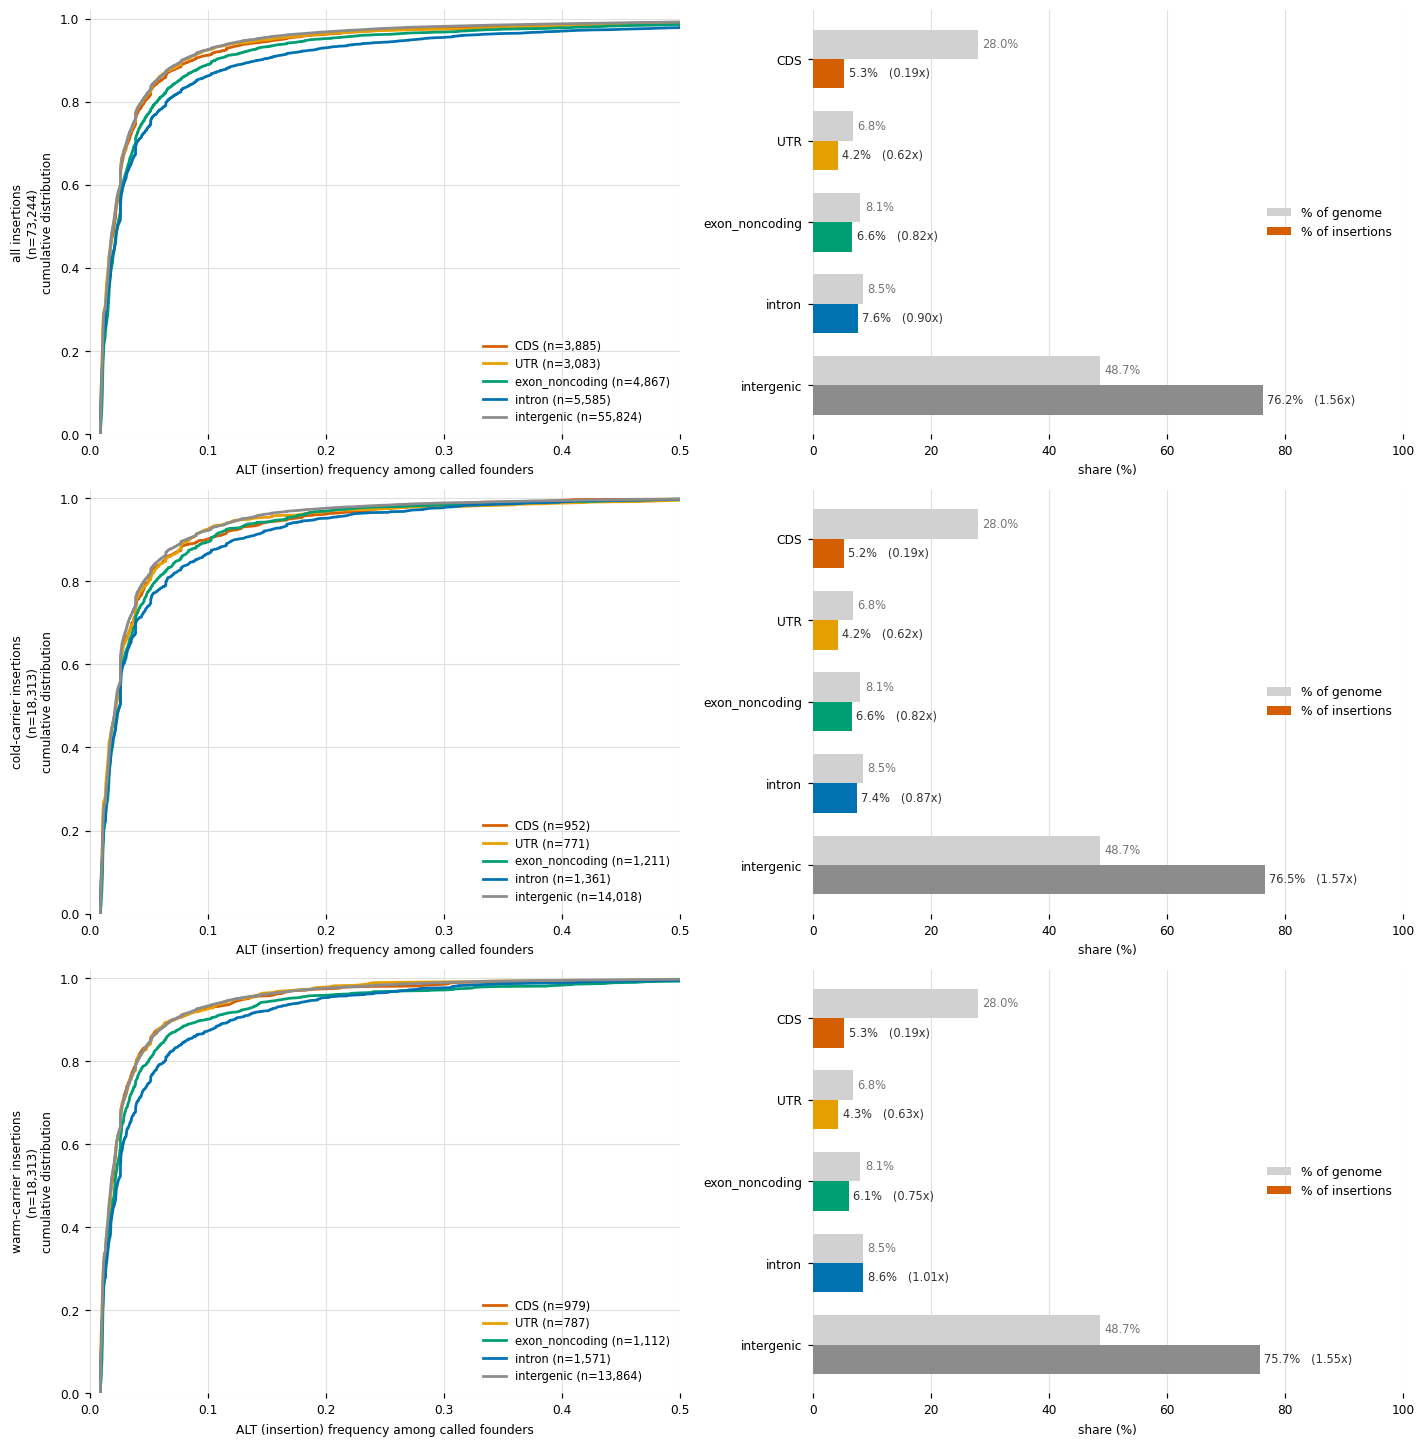

columns: [1] all insertions | [2] cold-carrier insertions | [3] warm-carrier insertions
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         3,885   5.3%  0.19x           952   5.2%  0.19x           979   5.3%  0.19x
UTR                  6.8         3,083   4.2%  0.62x           771   4.2%  0.62x           787   4.3%  0.63x
exon_noncoding       8.1         4,867   6.6%  0.82x         1,211   6.6%  0.82x         1,112   6.1%  0.75x
intron               8.5         5,585   7.6%  0.90x         1,361   7.4%  0.87x         1,571   8.6%  1.01x
intergenic          48.7        55,824  76.2%  1.56x        14,018  76.5%  1.57x        13,864  75.7%  1.55x



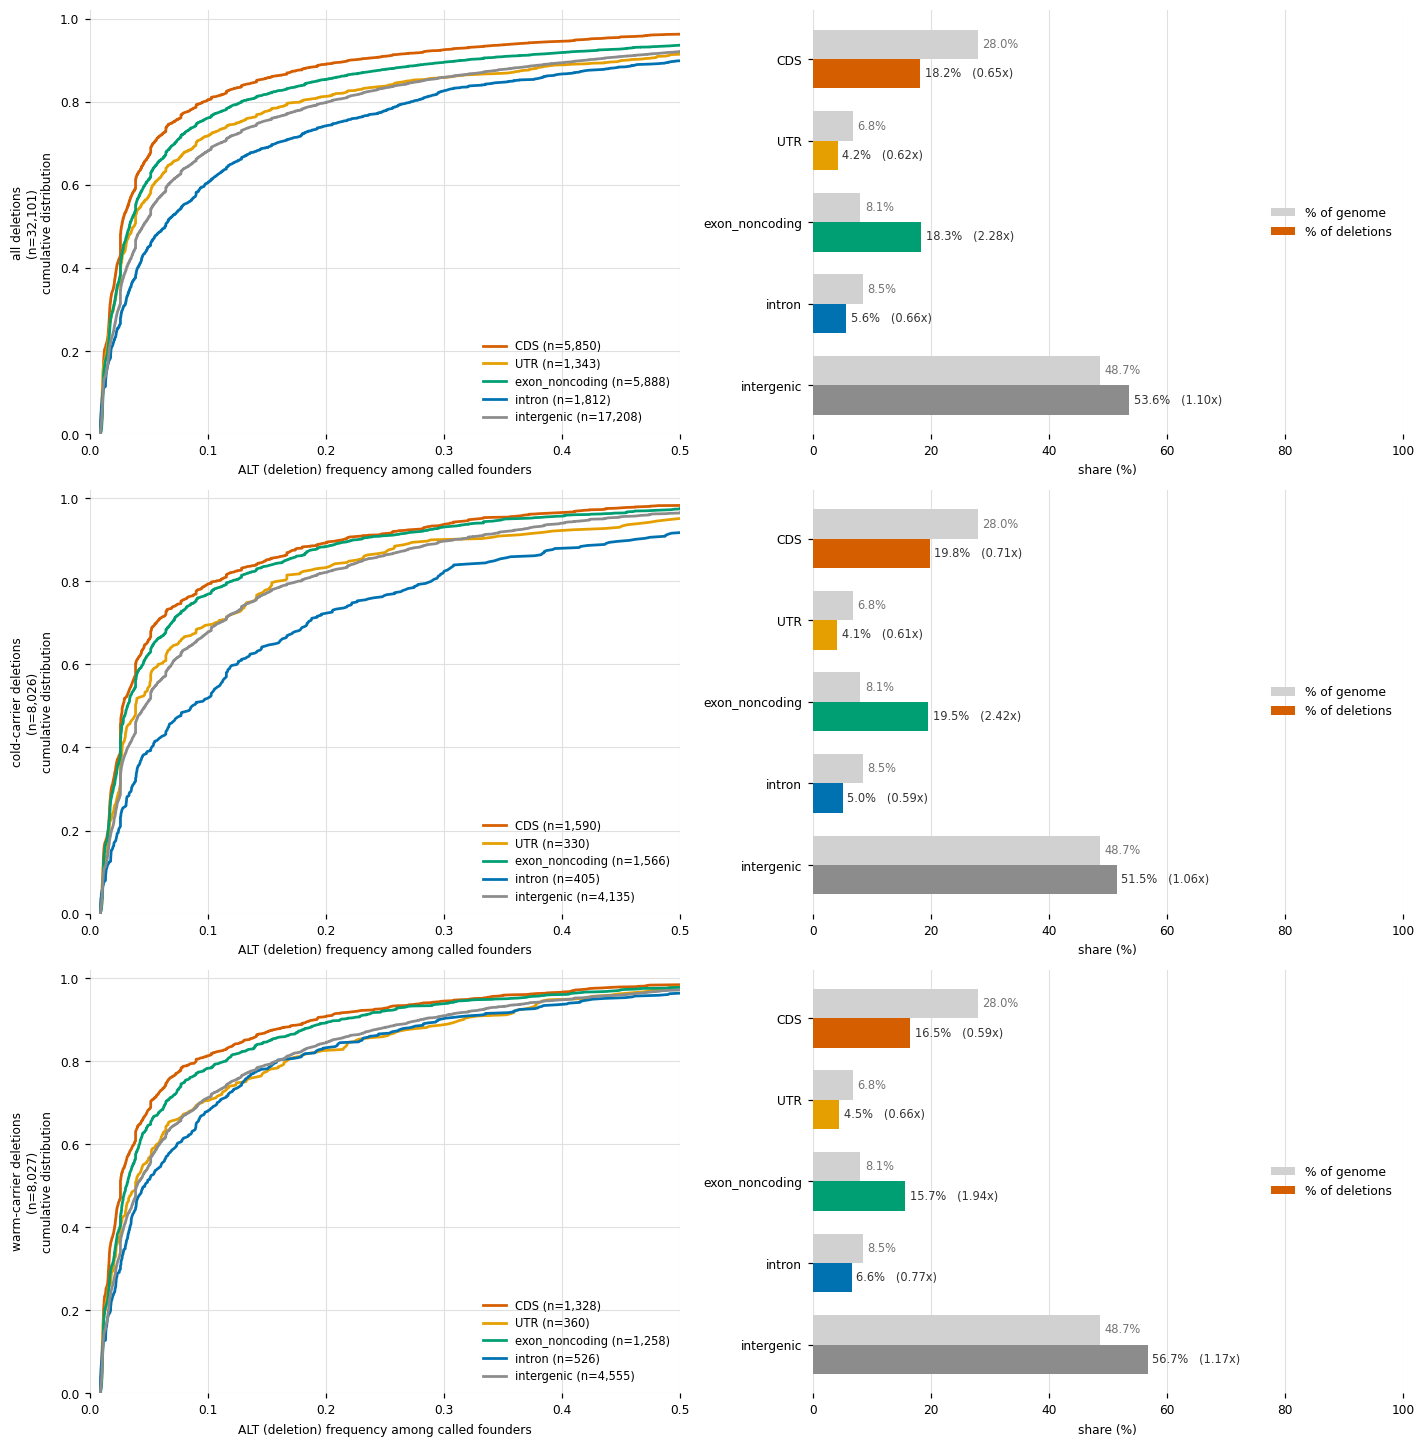

columns: [1] all deletions | [2] cold-carrier deletions | [3] warm-carrier deletions
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         5,850  18.2%  0.65x         1,590  19.8%  0.71x         1,328  16.5%  0.59x
UTR                  6.8         1,343   4.2%  0.62x           330   4.1%  0.61x           360   4.5%  0.66x
exon_noncoding       8.1         5,888  18.3%  2.28x         1,566  19.5%  2.42x         1,258  15.7%  1.94x
intron               8.5         1,812   5.6%  0.66x           405   5.0%  0.59x           526   6.6%  0.77x
intergenic          48.7        17,208  53.6%  1.10x         4,135  51.5%  1.06x         4,555  56.7%  1.17x

cold vs warm, within each carrier-count stratum (the like-for-like comparison):
  insertions n_alt     n cold  n warm  CDS cold  CDS warm  genic cold  genic warm  TE cold  TE warm
             2-3        9,604   9,603      5.2%      5.4%       23.0%       22.7

In [6]:

STRATA=[(2,3),(4,7),(8,20),(21,10**6)]
def carrier_groups(D):
    g=pd.Series("mid",index=D.index)
    for a,b in STRATA:
        sel=(D.n_alt>=a)&(D.n_alt<=b)
        q=D.loc[sel,"carrier_bio1"].quantile([.25,.75])
        g[sel]=np.where(D.loc[sel,"carrier_bio1"]<=q.iloc[0],"cold",np.where(D.loc[sel,"carrier_bio1"]>=q.iloc[1],"warm","mid"))
    return g
ALL["cgrp"]=carrier_groups(ALL); DEL["cgrp"]=carrier_groups(DEL)
IC,IW=ALL[ALL.cgrp=="cold"],ALL[ALL.cgrp=="warm"]
DC,DW=DEL[DEL.cgrp=="cold"],DEL[DEL.cgrp=="warm"]
for nm,c,w in (("insertions",IC,IW),("deletions",DC,DW)):
    print(f"{nm}: cold-carrier n={len(c):,} (median carrier bio1 {c.carrier_bio1.median():.1f} C, median freq {c.freq.median():.4f}) | "
          f"warm-carrier n={len(w):,} ({w.carrier_bio1.median():.1f} C, freq {w.freq.median():.4f})")

block([(ALL,"all insertions\n(n=%s)"%f"{len(ALL):,}"),
       (IC,"cold-carrier insertions\n(n=%s)"%f"{len(IC):,}"),
       (IW,"warm-carrier insertions\n(n=%s)"%f"{len(IW):,}")],
      "insertion","ins_spectrum_share_by_carrier_climate_fixed"+TAG+".png")
print()
block([(DEL,"all deletions\n(n=%s)"%f"{len(DEL):,}"),
       (DC,"cold-carrier deletions\n(n=%s)"%f"{len(DC):,}"),
       (DW,"warm-carrier deletions\n(n=%s)"%f"{len(DW):,}")],
      "deletion","del_spectrum_share_by_carrier_climate_fixed"+TAG+".png")

print("\ncold vs warm, within each carrier-count stratum (the like-for-like comparison):")
labs=[f"{a}" if a==b else (f"{a}-{b}" if b<10**5 else f"{a}+") for a,b in STRATA]
for nm,T in (("insertions",ALL),("deletions",DEL)):
    print(f"  {nm:<11}{'n_alt':<8}{'n cold':>8}{'n warm':>8}{'CDS cold':>10}{'CDS warm':>10}{'genic cold':>12}{'genic warm':>12}{'TE cold':>9}{'TE warm':>9}")
    for (a,b),l in zip(STRATA,labs):
        s=T[(T.n_alt>=a)&(T.n_alt<=b)]; c=s[s.cgrp=="cold"]; w=s[s.cgrp=="warm"]
        print(f"  {'':<11}{l:<8}{len(c):>8,}{len(w):>8,}{100*(c.genic=='CDS').mean():>9.1f}%{100*(w.genic=='CDS').mean():>9.1f}%"
              f"{100*(c.genic!='intergenic').mean():>11.1f}%{100*(w.genic!='intergenic').mean():>11.1f}%{100*c.te_overlap.mean():>8.1f}%{100*w.te_overlap.mean():>8.1f}%")

print("\nSIZE CHECK -- cold-carrier SVs are longer, and overlap probability grows with length:")
print(f"  {'':<11}{'n_alt':<8}{'ins size cold':>14}{'ins size warm':>14}{'del size cold':>14}{'del size warm':>14}{'del midCDS cold':>16}{'del midCDS warm':>16}")
for (a,b),l in zip(STRATA,labs):
    si=ALL[(ALL.n_alt>=a)&(ALL.n_alt<=b)]; sd=DEL[(DEL.n_alt>=a)&(DEL.n_alt<=b)]
    ic,iw=si[si.cgrp=="cold"],si[si.cgrp=="warm"]; dc,dw=sd[sd.cgrp=="cold"],sd[sd.cgrp=="warm"]
    print(f"  {'':<11}{l:<8}{ic['size'].median():>13,.0f} {iw['size'].median():>13,.0f} {dc['size'].median():>13,.0f} {dw['size'].median():>13,.0f} "
          f"{100*(dc.genic_mid=='CDS').mean():>15.1f}%{100*(dw.genic_mid=='CDS').mean():>15.1f}%")
DEL["szq"]=pd.qcut(DEL['size'],5,labels=False); cells=[]
for a,b in STRATA:
    for q in range(5):
        s=DEL[(DEL.n_alt>=a)&(DEL.n_alt<=b)&(DEL.szq==q)]; c=s[s.cgrp=="cold"]; w=s[s.cgrp=="warm"]
        if len(c)>50 and len(w)>50: cells.append(((c.genic=='CDS').mean()-(w.genic=='CDS').mean(),len(c)+len(w)))
cells=np.array(cells)
print(f"  deletions, CDS-overlap cold minus warm within stratum x size-quintile cells: >0 in {(cells[:,0]>0).sum()}/{len(cells)} cells, "
      f"weighted mean {100*np.average(cells[:,0],weights=cells[:,1]):+.1f} pp (unmatched: {100*((DC.genic=='CDS').mean()-(DW.genic=='CDS').mean()):+.1f} pp)")


## 1. Where the purged insertions land

Landing class of the flagged insertions against every other insertion above the carrier floor (left), and the
log2 ratio per class with a 95% bootstrap interval (right). Selection against the insertion itself would put
CDS clearly above zero.

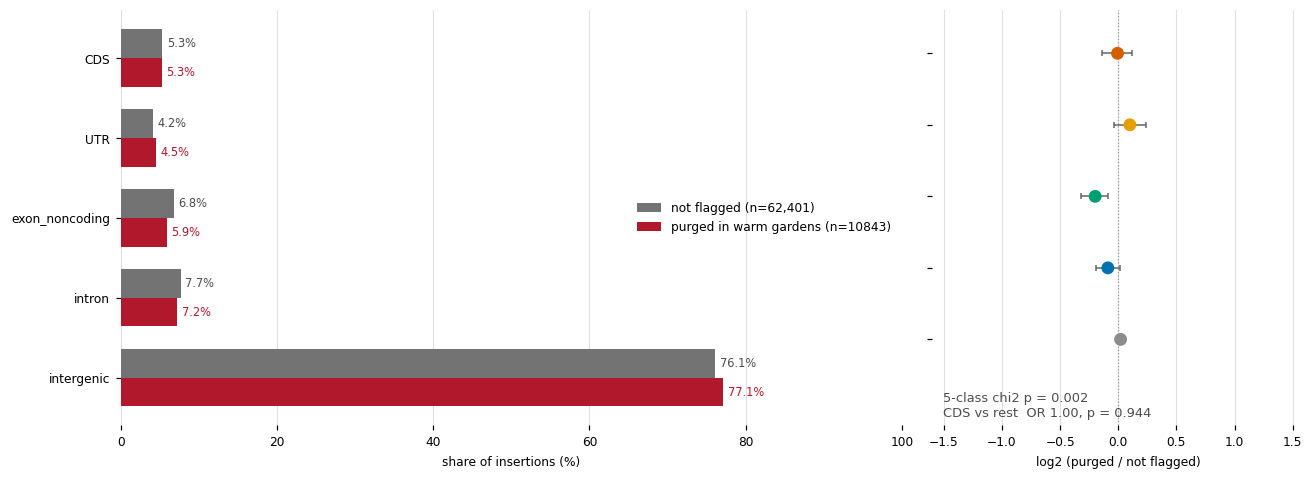

In [7]:

rng=np.random.default_rng(0)
def shares(df): return df.genic.value_counts(normalize=True).reindex(CLS).fillna(0).values*100
a,b=F.genic.values,R.genic.values
draws=np.empty((2000,len(CLS)))
for i in range(2000):
    qa=pd.Series(rng.choice(a,a.size)).value_counts(normalize=True).reindex(CLS).fillna(0).values
    qb=pd.Series(rng.choice(b,b.size)).value_counts(normalize=True).reindex(CLS).fillna(0).values
    draws[i]=np.log2(np.maximum(qa,1e-9)/np.maximum(qb,1e-9))
lfc=np.log2(shares(F)/shares(R)); ci=np.percentile(draws,[2.5,97.5],axis=0)

fig,ax=plt.subplots(1,2,figsize=(12,4.4),gridspec_kw=dict(width_ratios=[2.1,1]))
style(ax[0],axis="x"); style(ax[1],axis="x")
yy=np.arange(len(CLS))[::-1]; h=0.36
ax[0].barh(yy+h/2,shares(R),height=h,color=REST,linewidth=0,label=f"not flagged (n={len(R):,})")
ax[0].barh(yy-h/2,shares(F),height=h,color=FLAG,linewidth=0,label=f"purged in warm gardens (n={len(F)})")
for y,vr,vf in zip(yy,shares(R),shares(F)):
    ax[0].annotate(f"{vr:.1f}%",(vr,y+h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.3")
    ax[0].annotate(f"{vf:.1f}%",(vf,y-h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color=FLAG)
ax[0].set_yticks(yy); ax[0].set_yticklabels(CLS); ax[0].set_xlim(0,100); ax[0].set_xlabel("share of insertions (%)")
ax[0].legend(frameon=False,fontsize=8,loc="center right")

ax[1].axvline(0,color="0.6",ls=":",lw=0.8)
ax[1].errorbar(lfc,yy,xerr=[lfc-ci[0],ci[1]-lfc],fmt="none",ecolor="0.4",elinewidth=1,capsize=2)
ax[1].scatter(lfc,yy,color=[CCOL[c] for c in CLS],s=55,zorder=3)
ax[1].set_yticks(yy); ax[1].set_yticklabels([]); ax[1].set_xlim(-1.6,1.6); ax[1].set_ylim(yy.min()-1.2,yy.max()+0.6)
ax[1].set_xlabel("log2 (purged / not flagged)")
tab=pd.crosstab(J.genic,J.flagA).reindex(CLS)
chi=stats.chi2_contingency(tab.values)[1]
cds=stats.fisher_exact([[tab.loc["CDS",True],tab[True].sum()-tab.loc["CDS",True]],[tab.loc["CDS",False],tab[False].sum()-tab.loc["CDS",False]]])
stat(ax[1],f"5-class chi2 p {pfmt(chi)}\nCDS vs rest  OR {cds[0]:.2f}, p {pfmt(cds[1])}",loc=(0.03,0.02))
fig.tight_layout(); fig.savefig(f"{G}/plots/ins_landing_purged_vs_rest_fixed{TAG}.png",dpi=130,bbox_inches="tight"); plt.show()


## 2. What does separate them: the origin climate of the founders that carry them

Mean origin bio1 of the founders carrying each insertion, purged vs not. Because a rare insertion's carrier
mean is close to a single founder's origin while a common one regresses to the panel mean, the same
comparison is repeated within p0 quartiles.

Read this with the definition in mind: flag A matches SNPs on p0 only, so an insertion carried by
cold-origin founders is flagged whenever cold-origin *lineages* lose ground in warm gardens — no selection
on the insertion needed. `sv_temporal_climate_matched.ipynb` / `sv_purging_fixed.ipynb` add the
carrier-climate matching that this flag lacks.

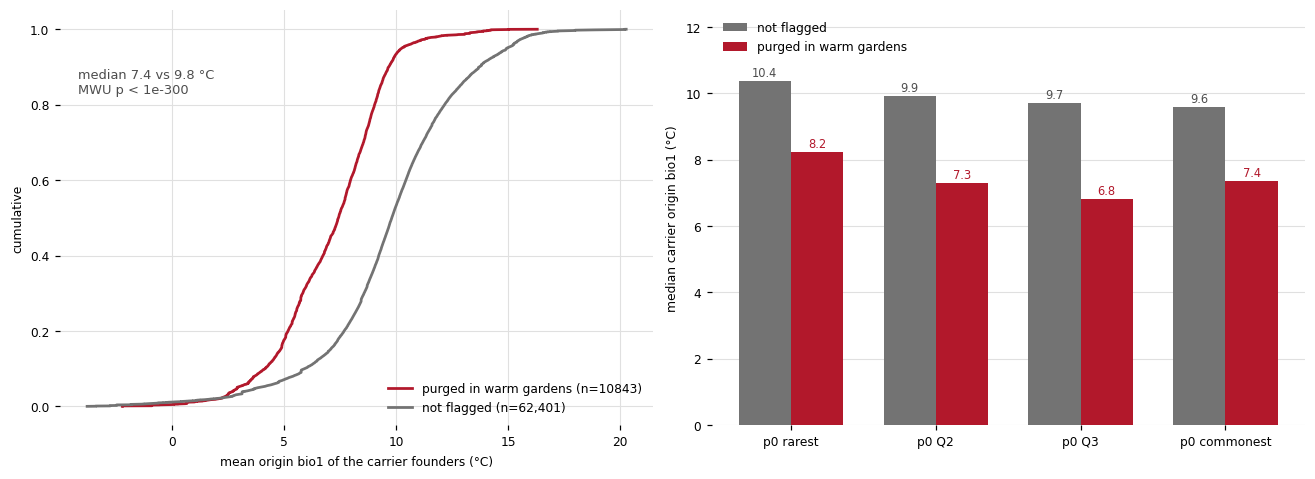

In [8]:

fig,ax=plt.subplots(1,2,figsize=(12,4.4))
style(ax[0]); style(ax[1],axis="y")
for d,c,lab in ((F,FLAG,f"purged in warm gardens (n={len(F)})"),(R,REST,f"not flagged (n={len(R):,})")):
    v=np.sort(d.carrier_bio1.values); ax[0].plot(v,np.arange(1,v.size+1)/v.size,color=c,lw=1.8,label=lab)
ax[0].set_xlabel("mean origin bio1 of the carrier founders (°C)"); ax[0].set_ylabel("cumulative")
ax[0].legend(frameon=False,fontsize=8,loc="lower right")
mw=stats.mannwhitneyu(F.carrier_bio1,R.carrier_bio1)
stat(ax[0],f"median {F.carrier_bio1.median():.1f} vs {R.carrier_bio1.median():.1f} °C\nMWU p {pfmt(mw.pvalue)}",loc=(0.03,0.80))

J["p0q"]=pd.qcut(J.p0,4,labels=["rarest","Q2","Q3","commonest"])
g=J.groupby(["p0q","flagA"],observed=True).carrier_bio1.median().unstack()
x=np.arange(4); w=0.36
ax[1].bar(x-w/2,g[False],width=w,color=REST,linewidth=0,label="not flagged")
ax[1].bar(x+w/2,g[True],width=w,color=FLAG,linewidth=0,label="purged in warm gardens")
for i,(r_,f_) in enumerate(zip(g[False],g[True])):
    ax[1].annotate(f"{r_:.1f}",(i-w/2,r_),xytext=(0,3),textcoords="offset points",ha="center",fontsize=7.5,color="0.3")
    ax[1].annotate(f"{f_:.1f}",(i+w/2,f_),xytext=(0,3),textcoords="offset points",ha="center",fontsize=7.5,color=FLAG)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"p0 {q}" for q in g.index]); ax[1].set_ylim(0,12.5)
ax[1].set_ylabel("median carrier origin bio1 (°C)"); ax[1].legend(frameon=False,fontsize=8,loc="upper left")
fig.tight_layout(); fig.savefig(f"{G}/plots/ins_purged_carrier_origin_fixed{TAG}.png",dpi=130,bbox_inches="tight"); plt.show()


## Supporting checks (numbers only)

In [9]:

B=J.flagB
print(f"Alternative flag B: s below matched-SNP 10th pct in >= {P['min_hot']} of {len(P['hot_sites'])} hot gardens -> {B.sum()} insertions; "
      f"overlap with A = {(J.flagA&B).sum()} (independence ~{J.flagA.sum()*B.sum()/len(J):.0f}). "
      f"Same rule at {len(P['cold_sites'])} cold gardens flags {(J.n_cold_low>=P['min_hot']).sum()}: per-site s is shared across gardens through carriers, so A is the climate-differential definition.")
tabB=pd.crosstab(J.genic,B).reindex(CLS)
print(f"Under B: CDS {100*tabB.loc['CDS',True]/tabB[True].sum():.1f}% flagged vs {100*tabB.loc['CDS',False]/tabB[False].sum():.1f}% rest; "
      f"genic-vs-intergenic OR {stats.fisher_exact([[tabB[True].sum()-tabB.loc['intergenic',True],tabB.loc['intergenic',True]],[tabB[False].sum()-tabB.loc['intergenic',False],tabB.loc['intergenic',False]]])[0]:.2f} (purged set slightly MORE intergenic).")
print(f"\nOther properties, A flagged vs rest: TE-overlap at site {100*F.te_overlap.mean():.1f}% vs {100*R.te_overlap.mean():.1f}% "
      f"(Fisher p {pfmt(stats.fisher_exact([[F.te_overlap.sum(),(~F.te_overlap).sum()],[R.te_overlap.sum(),(~R.te_overlap).sum()]])[1])}); "
      f"median size {F['size'].median():.0f} vs {R['size'].median():.0f} bp; median p0 {F.p0.median():.3f} vs {R.p0.median():.3f}.")
print(f"\nNo-threshold check, beta(bio1) percentile among matched SNPs by class (0.5 = SNP-like):")
for c in CLS:
    v=J.loc[J.genic==c,'pct_beta1']; print(f"  {c:<15} n={v.size:>5}  mean {v.mean():.3f}")
print(f"  CDS vs intergenic MWU p {pfmt(stats.mannwhitneyu(J.loc[J.genic=='CDS','pct_beta1'],J.loc[J.genic=='intergenic','pct_beta1']).pvalue)}")
print("\nCALL-RATE SENSITIVITY (no call-rate floor is applied above; SVs are called in fewer founders than SNPs):")
print(f"  insertion call rate: median {J.call_rate.median():.2f}, {100*(J.call_rate<0.9).mean():.0f}% below 0.9")
for lo in (0.0,0.5,0.9):
    j=J[J.call_rate>=lo]; t=pd.crosstab(j.genic,j.flagA).reindex(CLS); f_,r_=j[j.flagA],j[~j.flagA]
    o_,p_=stats.fisher_exact([[t.loc["CDS",True],t[True].sum()-t.loc["CDS",True]],[t.loc["CDS",False],t[False].sum()-t.loc["CDS",False]]])
    print(f"  call >= {lo:.1f}: n={len(j):>6,}  flagged {100*j.flagA.mean():4.1f}%  CDS {100*(f_.genic=='CDS').mean():.1f} vs {100*(r_.genic=='CDS').mean():.1f}% "
          f"(OR {o_:.2f}, p {pfmt(p_)})  carrier bio1 {f_.carrier_bio1.median():.1f} vs {r_.carrier_bio1.median():.1f} C")
print(f"\nTested set vs every insertion above the carrier floor: intron {100*(J.genic=='intron').mean():.1f}% vs {100*(ALL.genic=='intron').mean():.1f}% of {len(ALL):,}; "
      f"TE-overlap {100*J.te_overlap.mean():.1f}% vs {100*ALL.te_overlap.mean():.1f}%; median size {J['size'].median():.0f} vs {ALL['size'].median():.0f} bp.")


Alternative flag B: s below matched-SNP 10th pct in >= 3 of 7 hot gardens -> 9740 insertions; overlap with A = 4376 (independence ~1442). Same rule at 11 cold gardens flags 9234: per-site s is shared across gardens through carriers, so A is the climate-differential definition.
Under B: CDS 5.8% flagged vs 5.2% rest; genic-vs-intergenic OR 0.97 (purged set slightly MORE intergenic).

Other properties, A flagged vs rest: TE-overlap at site 29.7% vs 29.9% (Fisher p = 0.666); median size 654 vs 531 bp; median p0 0.021 vs 0.020.

No-threshold check, beta(bio1) percentile among matched SNPs by class (0.5 = SNP-like):
  CDS             n= 3885  mean 0.407
  UTR             n= 3083  mean 0.414
  exon_noncoding  n= 4867  mean 0.414
  intron          n= 5585  mean 0.432
  intergenic      n=55824  mean 0.411


  CDS vs intergenic MWU p = 0.408

CALL-RATE SENSITIVITY (no call-rate floor is applied above; SVs are called in fewer founders than SNPs):
  insertion call rate: median 0.84, 68% below 0.9
  call >= 0.0: n=73,244  flagged 14.8%  CDS 5.3 vs 5.3% (OR 1.00, p = 0.944)  carrier bio1 7.4 vs 9.8 C


  call >= 0.5: n=65,410  flagged 14.4%  CDS 5.3 vs 5.2% (OR 1.01, p = 0.802)  carrier bio1 7.4 vs 9.9 C
  call >= 0.9: n=23,343  flagged 14.1%  CDS 5.3 vs 4.5% (OR 1.18, p = 0.048)  carrier bio1 7.4 vs 10.1 C

Tested set vs every insertion above the carrier floor: intron 7.6% vs 7.6% of 73,244; TE-overlap 29.9% vs 29.9%; median size 544 vs 544 bp.


## Summary

**The fix and the full spectrum change the set, not the answer.** Judged on their own carriers and with only
private records removed, 73,244 insertions are scored (vs 2,546 before) and 10,843 are purged more than
p0-matched SNPs (14.8%; 10% expected).

1. **No genic enrichment — now across the whole spectrum.** Purged insertions land exactly where the other
   insertions do: CDS 5.3% vs 5.3% (OR 1.00, p = 0.94), ~77% intergenic, and their per-class frequency
   spectra match row 1. The 5-class χ² is nominally significant at this n (p = 0.002) from sub-point shifts
   (slightly fewer non-coding-exon and intronic, slightly more intergenic among the purged) — the opposite of
   selection against gene disruption. The no-threshold check agrees (CDS vs intergenic percentile,
   MWU p = 0.41).
2. **What sets them apart is who carries them.** Median carrier origin 7.4 vs 9.8 °C, the gap ≥ 2.2 °C in every
   p0 quartile; 7% of purged insertions have carriers averaging > 10 °C vs 47% of the rest. Flagged insertions
   are somewhat larger (median 654 vs 531 bp), as cold-carrier insertions are in the panel.

This is lineage turnover seen per variant: warm gardens remove cold-origin genotypes and their insertions go
with them, wherever the insertions sit. Flag A matches on p0 only, so on its own it cannot separate that from
selection on the insertions — the carrier-climate-matched analyses are the ones that can.

**Robustness.** The same picture holds for every filter in the comparison table (old position filter, per-allele
MAC ≥ 12, per-allele ≥ 2 with call rate ≥ 0.9 and p0 ≥ 0.02), and for call-rate floors of 0.5 and 0.9 on the
full-spectrum set (checks section). The only movement: at call rate ≥ 0.9, CDS OR 1.18, p = 0.048 — marginal,
single test among several, and absent at every other threshold.

Caveats: no call-rate floor, so 68% of the scored insertions are genotyped in < 90% of founders (their founder
frequency is n_alt / n_called); low-call records are flagged somewhat more often (≈ 19% below 0.5 vs ≈ 14%
above). The genome-share baseline counts TE-gene exons in `exon` but not in `gene`, so the intron / intergenic
expectations are slightly off (affects the §0 ratios, not the flagged-vs-rest comparisons).